# Sakila DVD Rental: Exploratory Analysis with pandas

**Author:** Maria Pupysheva · **Date:** October 2026

**Data:** MySQL sample database *sakila*, a fictional DVD rental store with payments,
customers, films and rentals (May 2005 – Feb 2006).

**Goal:** practise data exploration in pandas and answer basic business questions about
revenue, customers and the film catalogue. Results are cross-checked against earlier SQL queries.

**Tools:** Python 3.12 · pandas · SQLAlchemy · MySQL 8

## 1. Setup
Connect to the local MySQL server and load four tables into pandas DataFrames.
The password is requested at runtime, so it is never stored in the notebook.

In [1]:
import pandas as pd
import numpy as np
from sqlalchemy import create_engine
from getpass import getpass
import matplotlib as plt

pd.set_option("display.max_columns", 20)   # show all columns in wide tables

In [2]:
engine = create_engine(
    f"mysql+pymysql://root:{getpass('MySQL password: ')}@localhost:3306/sakila"
)

payments  = pd.read_sql("SELECT * FROM payment",  engine)
customers = pd.read_sql("SELECT * FROM customer", engine)
films     = pd.read_sql("SELECT * FROM film",     engine)
rentals   = pd.read_sql("SELECT * FROM rental",   engine)

# Size of each table
pd.DataFrame(
    {
        "rows":    [len(df) for df in (payments, customers, films, rentals)],
        "columns": [df.shape[1] for df in (payments, customers, films, rentals)],
    },
    index=["payments", "customers", "films", "rentals"],
)

,rows,columns
payments,16044,7
customers,599,9
films,1000,13
rentals,16044,7


## 2. Data overview
A first look at the structure, types, summary statistics and missing values of the tables.

### Q1. First rows of payments, last rows of films

In [3]:
display(payments.head())
display(films.tail())

,payment_id,customer_id,staff_id,rental_id,amount,payment_date,last_update
0,1,1,1,76,2.99,2005-05-25 11:30:37,2006-02-15 22:12:30
1,2,1,1,573,0.99,2005-05-28 10:35:23,2006-02-15 22:12:30
2,3,1,1,1185,5.99,2005-06-15 00:54:12,2006-02-15 22:12:30
3,4,1,2,1422,0.99,2005-06-15 18:02:53,2006-02-15 22:12:30
4,5,1,2,1476,9.99,2005-06-15 21:08:46,2006-02-15 22:12:30


,film_id,title,description,release_year,language_id,original_language_id,rental_duration,rental_rate,length,replacement_cost,rating,special_features,last_update
995,996,YOUNG LANGUAGE,A Unbelieveable Yarn of a Boat And a Database ...,2006,1,None,6,0.99,183,9.99,G,"Trailers,Behind the Scenes",2006-02-15 05:03:42
996,997,YOUTH KICK,A Touching Drama of a Teacher And a Cat who mu...,2006,1,None,4,0.99,179,14.99,NC-17,"Trailers,Behind the Scenes",2006-02-15 05:03:42
997,998,ZHIVAGO CORE,A Fateful Yarn of a Composer And a Man who mus...,2006,1,None,6,0.99,105,10.99,NC-17,Deleted Scenes,2006-02-15 05:03:42
998,999,ZOOLANDER FICTION,A Fateful Reflection of a Waitress And a Boat ...,2006,1,None,5,2.99,101,28.99,R,"Trailers,Deleted Scenes",2006-02-15 05:03:42
999,1000,ZORRO ARK,A Intrepid Panorama of a Mad Scientist And a B...,2006,1,None,3,4.99,50,18.99,NC-17,"Trailers,Commentaries,Behind the Scenes",2006-02-15 05:03:42


**Observation:** Each payment links a customer, a staff member and a rental, with an amount
and a timestamp. Films include descriptive fields (title, description, release year) and
business fields (rental rate, rental duration, replacement cost, rating).

### Q2. Structure of the films table
Column names, data types and non-null counts.

In [4]:
films.info()
films.dtypes

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   film_id               1000 non-null   int64         
 1   title                 1000 non-null   str           
 2   description           1000 non-null   str           
 3   release_year          1000 non-null   int64         
 4   language_id           1000 non-null   int64         
 5   original_language_id  0 non-null      object        
 6   rental_duration       1000 non-null   int64         
 7   rental_rate           1000 non-null   float64       
 8   length                1000 non-null   int64         
 9   replacement_cost      1000 non-null   float64       
 10  rating                1000 non-null   str           
 11  special_features      1000 non-null   str           
 12  last_update           1000 non-null   datetime64[us]
dtypes: datetime64[us](1), float64(

film_id                          int64
title                              str
description                        str
release_year                     int64
language_id                      int64
original_language_id            object
rental_duration                  int64
rental_rate                    float64
length                           int64
replacement_cost               float64
rating                             str
special_features                   str
last_update             datetime64[us]
dtype: object

**Observation:** The films table has 1000 rows and 13 columns.
- `original_language_id` is empty for all films → no information, can be dropped.
- All other columns are complete (no missing values).
- `release_year` is stored as int64 (8 bytes); int16 would be enough for years, which
  only matters for much larger datasets.
- `special_features` stores several values in one text field, so it would need splitting
  before analysing individual features.

### Q3. Distribution of payment amounts

In [5]:
display(payments["amount"].describe().round(2))

count    16044.00
mean         4.20
std          2.36
min          0.00
25%          2.99
50%          3.99
75%          4.99
max         11.99
Name: amount, dtype: float64

**Observation:** Payments range from 0 to 11.99.
- The mean (≈4.20) is higher than the median (3.99): a smaller number of large payments
  pulls the average up, so the distribution is right-skewed.
- 75% of payments are 4.99 or less; the most expensive payments sit in the top quarter.
- Some payments are exactly 0, which should be checked (free rentals, refunds, or errors).
- For a "typical" payment, the median is a better measure than the mean.

### Q4. Missing values in films, payments and rentals

In [6]:
def missing_values(df):
    counts = df.isna().sum()
    return counts[counts > 0]

display(missing_values(films))
display(missing_values(payments))
display(missing_values(rentals))
display(rentals['return_date'].isna().mean())

original_language_id    1000
dtype: int64

Series([], dtype: int64)

return_date    183
dtype: int64

np.float64(0.011406133133881825)

**Observation:**
- `films.original_language_id` is empty for all 1000 films → no information, can be dropped.
- `payments` has no missing values.
- `rentals.return_date` is missing for 183 of 16,044 rentals (≈1.1%). These DVDs were never
  returned, so the missing value is meaningful (open or possibly lost rentals) and should
  not be removed or filled. Worth checking how old these rentals are (see Q18).

### Q5. Unique customers and rented copies

In [7]:
print(f"Customers who paid at least once: {payments['customer_id'].nunique()}")
print(f"Total customers:                  {len(customers)}")
print(f"Unique DVD copies rented:         {rentals['inventory_id'].nunique()}")

Customers who paid at least once: 599
Total customers:                  599
Unique DVD copies rented:         4580


## 3. Filtering and sorting
Selecting columns, filtering rows by conditions, and sorting.

### Q6. Selected film columns

In [8]:
films[['title', 'length', 'rating']].head(10)

,title,length,rating
0,ACADEMY DINOSAUR,86,PG
1,ACE GOLDFINGER,48,G
2,ADAPTATION HOLES,50,NC-17
3,AFFAIR PREJUDICE,117,G
4,AFRICAN EGG,130,G
5,AGENT TRUMAN,169,PG
6,AIRPLANE SIERRA,62,PG-13
7,AIRPORT POLLOCK,54,R
8,ALABAMA DEVIL,114,PG-13
9,ALADDIN CALENDAR,63,NC-17


### Q7. Long PG films

In [9]:
films_pg_greater_150 = films[(films['rating']=='PG') & (films['length'] > 150)][['title', 'length', 'rating']]
long_pg = len(films_pg_greater_150)
print(f"Number of long PG films: {long_pg}")
pg_tot = (films['rating'] == 'PG').sum()
print(f"PG films total: {pg_tot}")
print(f"The ratio of long PG films is: {long_pg/pg_tot:.1f}")
films_pg_greater_150

Number of long PG films: 39
PG films total: 194
The ratio of long PG films is: 0.2


,title,length,rating
5,AGENT TRUMAN,169,PG
73,BIRCH ANTITRUST,162,PG
87,BORN SPINAL,179,PG
120,CAROL TEXAS,151,PG
130,CENTER DINOSAUR,152,PG
200,CYCLONE FAMILY,176,PG
264,DYING MAKER,168,PG
289,EVERYONE CRAFT,163,PG
326,FOOL MOCKINGBIRD,158,PG
344,GABLES METROPOLIS,161,PG


**Observation:** 39 of the 194 PG films (20%) run longer than 150 minutes,
so roughly one in five family-rated films is a long feature.

### Q8. Films with "LOVE" in the title

In [10]:
love_f = films[films['title'].str.contains('LOVE', case=False)][['title', 'rating']]
love_f.sort_values('title', ascending = True)

,title,rating
373,GRAFFITI LOVE,PG
447,IDAHO LOVE,PG-13
448,IDENTITY LOVER,PG-13
457,INDIAN LOVE,NC-17
510,LAWRENCE LOVE,NC-17
534,LOVE SUICIDES,R
535,LOVELY JINGLE,PG
536,LOVER TRUMAN,G
537,LOVERBOY ATTACKS,PG-13
851,STRANGELOVE DESIRE,NC-17


**Observation:** 10 films contain "LOVE" in the title, matching the SQL result.
The search matches substrings, so titles like LOVER, LOVELY and STRANGELOVE are included too.

### Q9. The 10 longest films

In [11]:
largest_10 = films.sort_values('length', ascending=False)[['title', 'length']].head(10)
max_len = films["length"].max()
print(f"Longest film length: {max_len} min")
print(f"Films with that length: {(films['length'] == max_len).sum()}")
largest_10

Longest film length: 185 min
Films with that length: 10


,title,length
425,HOME PITY,185
348,GANGS PRIDE,185
608,MUSCLE BRIGHT,185
689,POND SEATTLE,185
140,CHICAGO NORTH,185
871,SWEET BROTHERHOOD,185
990,WORST BANGER,185
816,SOLDIERS EVOLUTION,185
211,DARN FORRESTER,185
181,CONTROL ANTHEM,185


**Observation:** The maximum film length is 185 minutes, and exactly 10 films share it,
so the "top 10 longest" is a 10-way tie rather than a ranking.

### Q10. Cheapest and most expensive payments

In [12]:
pay_bound = payments[(payments['amount']==payments.loc[payments['amount']>0, 'amount'].min()) | (payments['amount'] == payments['amount'].max())]
display(pay_bound["amount"].value_counts())
pay_bound.head()

amount
0.99     2977
11.99      10
Name: count, dtype: int64

,payment_id,customer_id,staff_id,rental_id,amount,payment_date,last_update
1,2,1,1,573,0.99,2005-05-28 10:35:23,2006-02-15 22:12:30
3,4,1,2,1422,0.99,2005-06-15 18:02:53,2006-02-15 22:12:30
7,8,1,2,2363,0.99,2005-06-18 13:33:59,2006-02-15 22:12:30
17,18,1,1,8074,0.99,2005-07-28 17:33:39,2006-02-15 22:12:30
18,19,1,2,8116,0.99,2005-07-28 19:20:07,2006-02-15 22:12:30


**Observation:** 2977 payments were 0.99 (the cheapest rental) and only 10 were 11.99
(the most expensive). Very high payments are rare, which matches the right-skewed
distribution from Q3: a small number of large payments pulls the mean above the median.

## 4. Aggregation
Totals, averages and counts, overall and per group.

### Q11. Overall revenue

In [13]:
rev_pay = payments['amount'].sum()
avg_pay = payments['amount'].mean()
n_pay = len(payments)
print(f"The total revenue is: {rev_pay}")
print(f"The average payment is: {avg_pay:.2f}")
print(f"The number of payments is: {n_pay}")

The total revenue is: 67406.56
The average payment is: 4.20
The number of payments is: 16044


### Q12. Films per rating

In [14]:
films['rating'].value_counts()

rating
PG-13    223
NC-17    210
R        195
PG       194
G        178
Name: count, dtype: int64

### Q13. Top 10 customers by revenue

In [15]:
top_customers = payments.groupby('customer_id').agg(total_paid=('amount', 'sum'), bought=('payment_id', 'count')).sort_values(by='total_paid',ascending=False).head(10)
top_customers.reset_index().merge(customers[["customer_id", "first_name", "last_name"]], on="customer_id")

,customer_id,total_paid,bought,first_name,last_name
0,526,221.55,45,KARL,SEAL
1,148,216.54,46,ELEANOR,HUNT
2,144,195.58,42,CLARA,SHAW
3,178,194.61,39,MARION,SNYDER
4,137,194.61,39,RHONDA,KENNEDY
5,459,186.62,38,TOMMY,COLLAZO
6,469,177.60,40,WESLEY,BULL
7,468,175.61,39,TIM,CARY
8,236,175.58,42,MARCIA,DEAN
9,181,174.66,34,ANA,BRADLEY


**Observation:** The top customer, KARL SEAL (id 526), paid 221.55. The top 10 customers
each paid between 174.66 and 221.55, matching the earlier SQL result.

### Q14. Film length by rating

In [16]:
films.groupby('rating').agg(
      avg_length=("length", "mean"),
      shortest=("length", "min"),
      longest=("length", "max"),
  ).round(1)

,avg_length,shortest,longest
rating,,,
G,111.1,47,185
NC-17,113.2,46,184
PG,112.0,46,185
PG-13,120.4,46,185
R,118.7,49,185


**Observation:** Average film length is similar across ratings (111–120 minutes).
PG-13 (120.4) and R (118.7) films are on average about 7–9 minutes longer than the others.
Every rating covers almost the same range (≈46–185 minutes), so the catalogue has short
and long films in all ratings; rating alone says little about length.

### Q15. Average rental rate by rental duration
Does a longer rental period come with a higher price?

In [17]:
films.groupby("rental_duration").agg(avg_rental_rate=("rental_rate", "mean")).round(2).reset_index()

,rental_duration,avg_rental_rate
0,3,2.83
1,4,2.97
2,5,3.20
3,6,2.90
4,7,3.02


**Observation:** Average rental rate varies only slightly with rental duration
(2.83–3.20 across 3–7 days), peaking at 5 days. There is no steady increase:
longer rental periods do not cost more, so price and rental duration appear to be
set independently.

## 5. Time analysis
Revenue and rental activity over time.

### Q16. Monthly revenue

,month,revenue,payments
0,2005-05,4823.44,1156
1,2005-06,9629.89,2311
2,2005-07,28368.91,6709
3,2005-08,24070.14,5686
4,2006-02,514.18,182


<Axes: title={'center': 'Revenue per month'}, xlabel='month'>

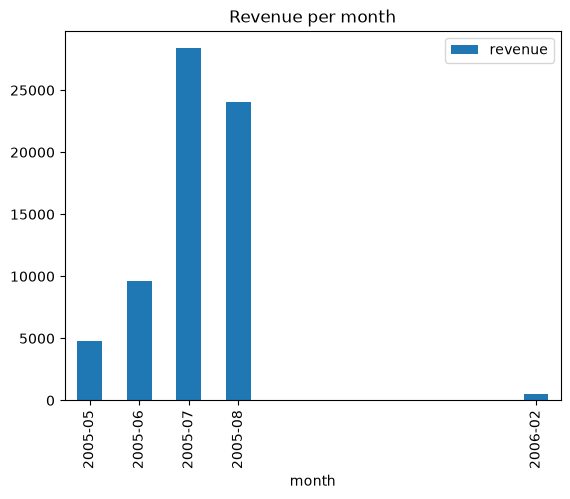

In [18]:
revenue_per_month = payments.groupby(payments['payment_date'].dt.to_period('M').rename('month')).agg(revenue=('amount', 'sum'), payments=('payment_id', 'count')).round(2).reset_index()
display(revenue_per_month)
revenue_per_month.plot(kind='bar', x='month', y='revenue', title = 'Revenue per month')

**Observation:** Revenue grew quickly from May to July 2005 (4.8k → 9.6k → 28.4k).
July and August are the strongest months, together ≈78% of total revenue (July alone ≈42%).
There is no data for September 2005 – January 2006, and February 2006 is very small (514),
so the dataset likely covers only part of that month. These gaps reflect data coverage,
not real drops in sales.

### Q17. Busiest day of the week

,weekday,rentals
0,Tuesday,2463
1,Sunday,2320
2,Saturday,2311
3,Friday,2272
4,Monday,2247
5,Wednesday,2231
6,Thursday,2200


,weekday,rentals
0,Tuesday,2463


<Axes: title={'center': 'Rentals per day'}, xlabel='weekday'>

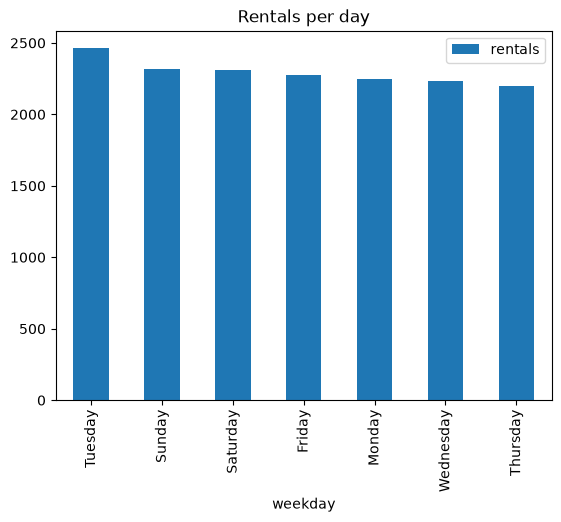

In [19]:
rented_per_day = rentals['rental_date'].dt.day_name().value_counts().reset_index().rename(columns={"rental_date": "weekday", "count": "rentals"})
display(rented_per_day)
display(rented_per_day.head(1))
rented_per_day.plot(kind='bar', x='weekday', y='rentals', title='Rentals per day')

**Observation:** Rentals are spread fairly evenly across the week (2,200–2,463 per weekday,
average ≈2,292). Tuesday is the busiest day, but only ≈7% above average; weekends and Friday
follow closely. The differences are small, so weekday is not a strong driver of rental demand
in this data.

### Q18. Unreturned rentals over time

In [20]:
# Rentals with no return date (DVD never returned)
open_rentals = rentals[rentals["return_date"].isna()]

share_open = len(open_rentals) / len(rentals)
print(f"Unreturned rentals: {len(open_rentals)} of {len(rentals):,} ({share_open:.2%})")

# Which months the unreturned rentals come from
open_per_month = (
    open_rentals
    .groupby(open_rentals["rental_date"].dt.to_period("M"))
    .agg(not_returned=("inventory_id", "count"))
    .rename_axis("month")
    .reset_index()
)
print(f"Rentals in Feb 2026: {(rentals["rental_date"].dt.to_period("M") == "2006-02").sum()}")
open_per_month



Unreturned rentals: 183 of 16,044 (1.14%)
Rentals in Feb 2026: 182


,month,not_returned
0,2005-08,1
1,2006-02,182


**Observation:** 183 rentals (1.14%) have no return date. Almost all of them (182) were made
in February 2006, the last month in the data, so they are most likely still in progress
when the data was captured rather than lost. Only 1 rental, from August 2005, is genuinely
overdue. Together with the low February revenue (Q16), this suggests the dataset ends partway
through February 2006.

## 6. Feature engineering
Creating new columns and reshaping data.

### Q19. Film length in hours

In [21]:
films.head()
films['length_hours'] = (films['length']/60).round(1)
films[['title', 'length', 'length_hours']].head()

,title,length,length_hours
0,ACADEMY DINOSAUR,86,1.4
1,ACE GOLDFINGER,48,0.8
2,ADAPTATION HOLES,50,0.8
3,AFFAIR PREJUDICE,117,2.0
4,AFRICAN EGG,130,2.2


New column `length_hours` (length in hours, 1 decimal) for easier reading of film durations.

### Q20. Short, medium and long films

In [22]:
edges = [0,59,120, films['length'].max()]
duration_names = ['Short', 'Medium', 'Long']
films['duration_type'] = pd.cut(films['length'], bins=edges, labels=duration_names)
display(films[['title', 'length', 'duration_type']].head())
display(films['duration_type'].value_counts().reset_index(name='count'))
films.loc[films["length"].isin([59, 60, 120, 121]), ["length", "duration_type"]].drop_duplicates().sort_values("length")

,title,length,duration_type
0,ACADEMY DINOSAUR,86,Medium
1,ACE GOLDFINGER,48,Short
2,ADAPTATION HOLES,50,Short
3,AFFAIR PREJUDICE,117,Medium
4,AFRICAN EGG,130,Long


,duration_type,count
0,Long,457
1,Medium,447
2,Short,96


,length,duration_type
170,59,Short
101,60,Medium
111,120,Medium
36,121,Long


**Observation:** Most films are either Long (457, 45.7%) or Medium (447, 44.7%);
only 96 (9.6%) are Short. The near-even Medium/Long split fits Q14, where average
lengths (111–120 min) sit right at the 120-minute boundary. Boundaries were checked:
59 → Short, 60 → Medium, 120 → Medium, 121 → Long.

### Q21. Films by rating and rental duration

In [23]:
rating_by_duration = pd.pivot_table(
    films,
    index="rating",
    columns="rental_duration",
    values="film_id",
    aggfunc="count",
    margins=True,             # adds totals
    margins_name="Total",
)
rating_by_duration
rating_by_duration.style.background_gradient(cmap="Blues")

rental_duration,3,4,5,6,7,Total
rating,,,,,,
G,49,28,33,39,29,178
NC-17,37,33,43,57,40,210
PG,36,41,33,39,45,194
PG-13,39,48,42,50,44,223
R,42,53,40,27,33,195
Total,203,203,191,212,191,1000


**Observation:** Films are spread fairly evenly across rental durations (191–212 per duration)
and ratings (178–223 per rating; totals match Q12). Individual combinations range from
27 (R, 6 days) to 57 (NC-17, 6 days). Some ratings lean slightly toward certain durations
(G toward 3 days, R toward 4 days), but there is no consistent pattern, so rental duration
does not appear to be assigned based on rating.

## 7. Summary

**Revenue**
- Total revenue: 67,406.56 from 16,044 payments (Q11).
- A typical payment is 3.99 (median); the mean is 4.20 because a smaller number of
  large payments (up to 11.99) pulls it up, so amounts are right-skewed (Q3, Q10).
- July 2005 brought the highest revenue (28,368.91, ≈42% of the total);
  July and August together ≈78% (Q16).

**Customers**
- All 599 customers made at least one payment (Q5).
- The top customer, KARL SEAL, paid 221.55 over 45 payments; the second, ELEANOR HUNT,
  paid almost the same (216.54) but needed 46 payments, so her rentals were cheaper
  on average (Q13).

**Film catalogue**
- 1000 films across 5 ratings, fairly evenly split; PG-13 is the largest group (223) (Q12).
- The longest films run 185 minutes (Q9); average length is similar across ratings
  (111–120 min) (Q14).
- Most films are Long (45.7%) or Medium (44.7%); only 9.6% are Short (Q20).
- Rental price is not linked to rental duration: average rates stay between 2.83 and 3.20
  for 3–7 days (Q15).

**Rentals and operations**
- Rentals are spread evenly across the week; Tuesday is the busiest day but only ≈7% above
  average (Q17).
- 4,580 distinct DVD copies were rented at least once (Q5).

**Data quality**
- `original_language_id` is empty for all 1000 films and carries no information (Q2, Q4).
- The data covers May–August 2005 and February 2006; there is no data for
  September 2005 – January 2006 (Q16).
- All 182 rentals from February 2006 are unreturned, and February revenue is very low (514),
  which confirms the dataset ends partway through February 2006 (Q16, Q18).
- Some payments are exactly 0 and should be verified (free rentals, refunds or errors) (Q3).